## 1. Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Load the data

In [2]:
def find_file(name):
    # look inside kaggle input folder first, then the current folder
    for root in ["/kaggle/input", "."]:
        for folder, _, files in os.walk(root):
            if name in files:
                return os.path.join(folder, name)
    raise FileNotFoundError(name + " not found - did you add the dataset?")

train_df = pd.read_csv(find_file("fashion-mnist_train.csv"))
test_df  = pd.read_csv(find_file("fashion-mnist_test.csv"))

print("train shape:", train_df.shape)
print("test shape :", test_df.shape)
train_df.head()

train shape: (60000, 785)
test shape : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Quick look at the data

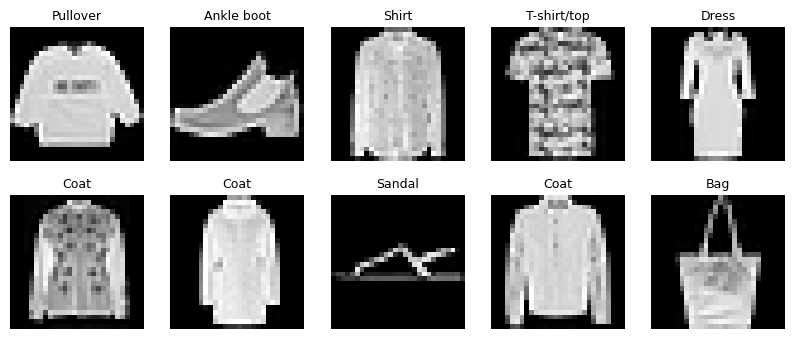

label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [3]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# first column is the label, the other 784 columns are pixels (0-255)
plt.figure(figsize=(10, 4))
for i in range(10):
    img = train_df.iloc[i, 1:].values.reshape(28, 28)
    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(class_names[train_df.iloc[i, 0]], fontsize=9)
    plt.axis("off")
plt.show()

# are the classes balanced?
print(train_df["label"].value_counts().sort_index())

## 4. Prepare the data for PyTorch

In [4]:
def prepare(df):
    X = df.drop("label", axis=1).values.astype("float32") / 255.0
    X = X.reshape(-1, 1, 28, 28)
    y = df["label"].values
    return torch.tensor(X), torch.tensor(y, dtype=torch.long)

X_train, y_train = prepare(train_df)
X_test,  y_test  = prepare(test_df)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_test,  y_test),  batch_size=256)

print(X_train.shape, y_train.shape)

torch.Size([60000, 1, 28, 28]) torch.Size([60000])


## 5. The model (a small CNN)
- **Conv2d** layers scan the image with small 3x3 filters and pick up patterns (edges first, then shapes)
- **ReLU** adds non-linearity so the network can learn more than straight lines
- **MaxPool** shrinks the image by half, keeping the strongest signals
- **Linear** layers at the end take all those features and give 10 scores, one per class

In [5]:
model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),   # 28x28 -> 28x28, 32 filters
    nn.ReLU(),
    nn.MaxPool2d(2),                              # -> 14x14
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),                              # -> 7x7
    nn.Flatten(),                                 # 64*7*7 = 3136 numbers
    nn.Linear(64 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, 10)                            # 10 classes
).to(device)

print(model)

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=3136, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)


## 6. Loss function and optimizer
- **CrossEntropyLoss** = standard loss for multi-class classification
- **Adam** = optimizer that updates the weights, learning rate 0.001 (just the usual default)

In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 7. Train the model
Each epoch = one full pass over the 60,000 training images. For every batch: forward pass -> compute loss -> backward pass (gradients) -> optimizer step. After each epoch I check the accuracy on the test set.

In [7]:
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            preds = model(X).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

EPOCHS = 5
train_losses, test_accs = [], []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()          # clear old gradients
        loss = loss_fn(model(X), y)    # forward pass + loss
        loss.backward()                # backward pass
        optimizer.step()               # update weights

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    acc = evaluate(model, test_loader)
    train_losses.append(avg_loss)
    test_accs.append(acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss: {avg_loss:.4f} | test accuracy: {acc*100:.2f}%")

Epoch 1/5 | loss: 0.4659 | test accuracy: 87.96%
Epoch 2/5 | loss: 0.3044 | test accuracy: 89.86%
Epoch 3/5 | loss: 0.2578 | test accuracy: 90.85%
Epoch 4/5 | loss: 0.2279 | test accuracy: 90.77%
Epoch 5/5 | loss: 0.2060 | test accuracy: 91.39%


## 8. Results

Final test accuracy: 91.39%


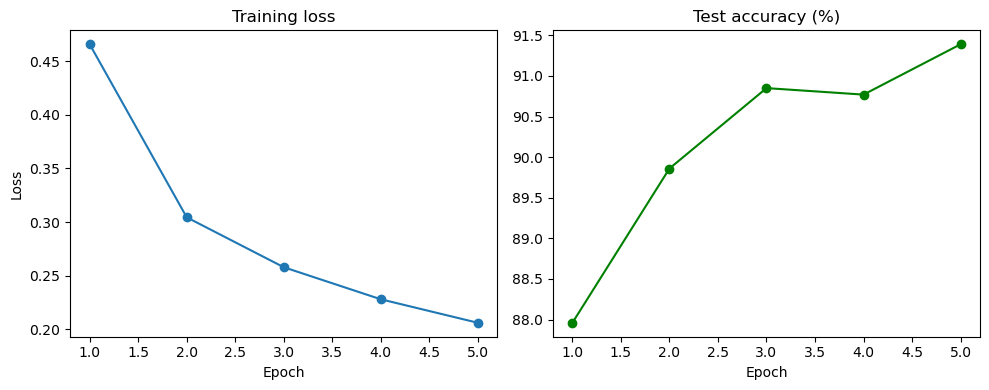

In [8]:
final_acc = evaluate(model, test_loader)
print(f"Final test accuracy: {final_acc*100:.2f}%")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), train_losses, marker="o")
plt.title("Training loss"); plt.xlabel("Epoch"); plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), [a * 100 for a in test_accs], marker="o", color="green")
plt.title("Test accuracy (%)"); plt.xlabel("Epoch")
plt.tight_layout()
plt.show()

### A few predictions (green = correct, red = wrong)

Accuracy: 91.02%


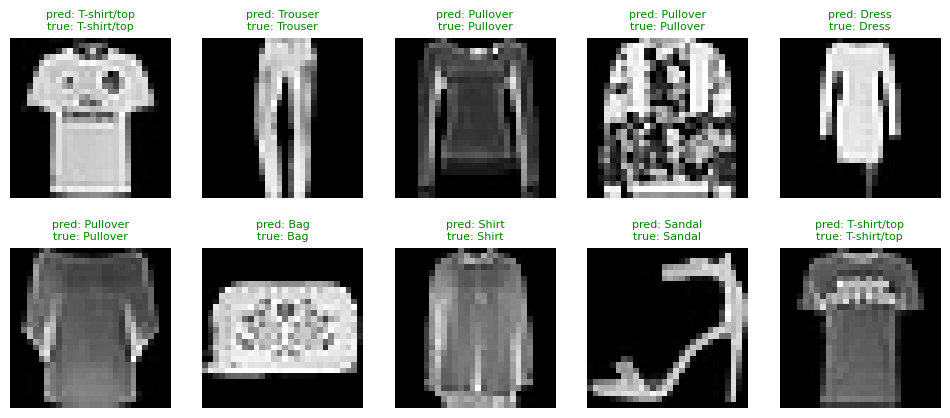

In [10]:
model.eval()

X_batch, y_batch = next(iter(test_loader))

with torch.no_grad():
    preds = model(X_batch.to(device)).argmax(dim=1).cpu()

# Calculate accuracy
correct = (preds == y_batch).sum().item()
total = len(y_batch)

accuracy = (correct / total) * 100

print(f"Accuracy: {accuracy:.2f}%")

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_batch[i].squeeze(), cmap="gray")

    color = "green" if preds[i] == y_batch[i] else "red"

    plt.title(
        f"pred: {class_names[preds[i]]}\ntrue: {class_names[y_batch[i]]}",
        color=color,
        fontsize=8
    )
    plt.axis("off")

plt.show()